# Issue #328 — Dynamic S1O1 allocator

Issue is the independent unit.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parents[2]
OUT=ROOT/'results/dynamic_allocator'

In [2]:
decision=json.loads((OUT/'decision.json').read_text()); decision

{'best_learned_arm': 'DYN_RIDGE',
 'best_static_interior': 'L075',
 'claim_boundary': 'RETROSPECTIVE_BASELINE_RELATIVE_EXPLORATION',
 'contract': 'BJ-UNIFIED-DYNAMIC-ALLOCATOR-001/v1',
 'disposition': 'ENDPOINT_RETAINED',
 'issue': 328,
 'promotion': False,
 'risk_gate_pass': True,
 'two_year_matched_lift': {'DYN_HGBR': 16800.45649012561,
  'DYN_RIDGE': 16800.45649012561,
  'L000': 16800.45649012561,
  'L025': 18193.630903224628,
  'L050': 21695.01772587704,
  'L075': 23248.522987825392,
  'L100': 24641.697400924404},
 'unlock_210': False}

In [3]:
perf=pd.read_csv(OUT/'performance.csv'); matched=pd.read_csv(OUT/'matched_performance.csv'); risk=pd.read_csv(OUT/'risk_diagnostics.csv'); perf

,issue_year,arm,ending_capital,capital_return,turnover_roi,hit_rate,mean_lambda,mean_allocation_hhi,active_issues,observable_issues,missing_issues,conservative_ending_capital,conservative_capital_return
0,2023,DYN_HGBR,101514.132791,0.015141,0.118292,0.080000,0.065206,0.025625,53,50,3,100746.132791,0.007461
1,2023,DYN_RIDGE,101514.132791,0.015141,0.118292,0.080000,0.071719,0.025625,53,50,3,100746.132791,0.007461
2,2023,L000,101514.132791,0.015141,0.118292,0.080000,0.000000,0.025625,53,50,3,100746.132791,0.007461
3,2023,L025,101514.132791,0.015141,0.118292,0.080000,0.250000,0.025664,53,50,3,100746.132791,0.007461
4,2023,L050,101514.132791,0.015141,0.118292,0.080000,0.500000,0.026279,53,50,3,100746.132791,0.007461
5,2023,L075,101241.148493,0.012411,0.096965,0.080000,0.750000,0.026785,53,50,3,100473.148493,0.004731
6,2023,L100,101241.148493,0.012411,0.096965,0.080000,1.000000,0.026880,53,50,3,100473.148493,0.004731
7,2024,DYN_HGBR,116708.290429,0.167083,1.087779,0.116667,0.026277,0.024742,66,60,6,115172.290429,0.151723
8,2024,DYN_RIDGE,116708.290429,0.167083,1.087779,0.116667,0.043084,0.024740,66,60,6,115172.290429,0.151723
9,2024,L000,116708.290429,0.167083,1.087779,0.116667,0.000000,0.024740,66,60,6,115172.290429,0.151723


In [4]:
matched.pivot(index='arm',columns='issue_year',values='total_lift').assign(two_year=lambda x:x.sum(axis=1)).sort_values('two_year',ascending=False)

issue_year,2023,2024,two_year
arm,,,
L100,2614.497924,22027.199477,24641.697401
L075,2614.497924,20634.025064,23248.522988
L050,2887.482222,18807.535503,21695.017726
L025,2887.482222,15306.148681,18193.630903
L000,2887.482222,13912.974268,16800.456490
DYN_HGBR,2887.482222,13912.974268,16800.456490
DYN_RIDGE,2887.482222,13912.974268,16800.456490


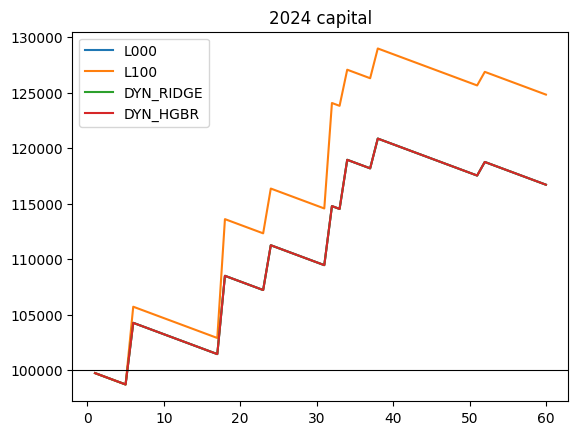

In [5]:
paths=pd.read_csv(OUT/'capital_paths.csv');
for arm in ['L000','L100','DYN_RIDGE','DYN_HGBR']:
 g=paths[(paths.issue_year==2024)&(paths.arm==arm)]; plt.plot(range(1,len(g)+1),g.capital_after,label=arm)
plt.axhline(100000,color='black',lw=.8);plt.legend();plt.title('2024 capital');plt.show()